In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"D:\AI-MSU")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

pred = pd.read_csv(PROCESSED_DIR / "isolation_forest_baseline.csv", parse_dates=["day"])
gt_files = list(RAW_DIR.rglob("insiders.csv"))
gt = pd.read_csv(gt_files[0])
gt["dataset"] = gt["dataset"].astype(str)
gt = gt[gt["dataset"].str.contains(r"4\.2", regex=True, na=False)].copy()
gt["start"] = pd.to_datetime(gt["start"], errors="coerce")
gt["end"] = pd.to_datetime(gt["end"], errors="coerce")

pred["inside_incident"] = False
for row in gt.itertuples(index=False):
    mask = ((pred["user"] == row.user) &
            (pred["day"] >= row.start.normalize()) &
            (pred["day"] <= row.end.normalize()))
    pred.loc[mask, "inside_incident"] = True

print("User-days inside known incident windows:", int(pred["inside_incident"].sum()))
print("Total user-days:", len(pred))

User-days inside known incident windows: 1892
Total user-days: 501000


In [2]:
rows = []
for percent in [99, 98, 95]:
    threshold = pred["anomaly_score"].quantile(percent / 100)
    flagged = pred["anomaly_score"] >= threshold
    incident_days = pred["inside_incident"]
    recall = flagged[incident_days].mean() if incident_days.any() else 0
    rows.append({
        "Score percentile": percent,
        "Threshold": round(threshold, 4),
        "Flagged user-days": int(flagged.sum()),
        "Flagged percent": round(flagged.mean() * 100, 2),
        "Incident-day recall": round(recall, 4)
    })

threshold_table = pd.DataFrame(rows)
display(threshold_table)

,Score percentile,Threshold,Flagged user-days,Flagged percent,Incident-day recall
0,99,0.0000,5010,1.0,0.0444
1,98,-0.0530,10020,2.0,0.0951
2,95,-0.1043,25050,5.0,0.1929


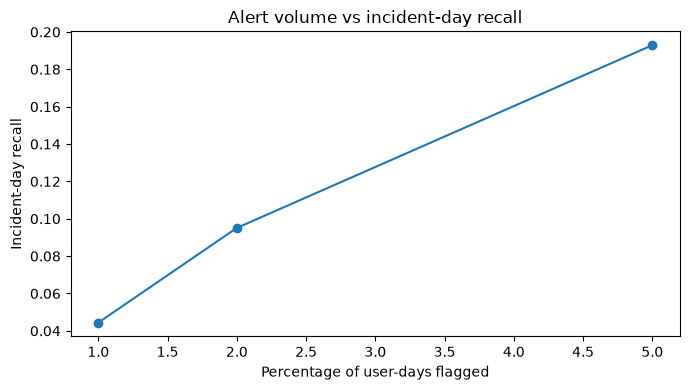

In [3]:
plt.figure(figsize=(7, 4))
plt.plot(threshold_table["Flagged percent"], threshold_table["Incident-day recall"], marker="o")
plt.xlabel("Percentage of user-days flagged")
plt.ylabel("Incident-day recall")
plt.title("Alert volume vs incident-day recall")
plt.tight_layout()
plt.show()

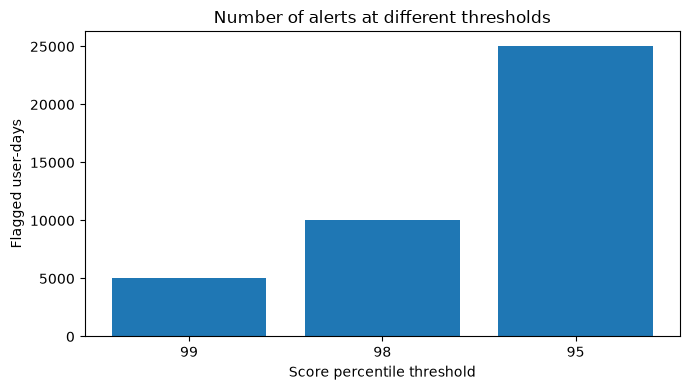

In [4]:
plt.figure(figsize=(7, 4))
plt.bar(threshold_table["Score percentile"].astype(str), threshold_table["Flagged user-days"])
plt.xlabel("Score percentile threshold")
plt.ylabel("Flagged user-days")
plt.title("Number of alerts at different thresholds")
plt.tight_layout()
plt.show()